# Analysis of the molecular dual-atom site catalyst databases

This notebook analyzes oxygen reduction reaction (ORR) energetics for dual-atom site
catalysts stored in five ASE databases. Every catalyst contains two metal atoms,
and each metal is treated as a distinct adsorption site.

The analysis proceeds as follows:

1. Read the catalyst and adsorbate metadata from the five databases.
2. Match OH, O and OOH calculations using both the catalyst name and the specific
   metal site; values from different sites are never combined.
3. Compare the x and z OOH orientations for each catalyst and adsorption site combination and retain the
   orientation with the lower total electronic energy.
4. Exclude pathways with E_ads(OH*) < 0 eV or E_ads(O*) > 4.92 eV.
5. Calculate the limiting potential and calculated ORR overpotential with the
   computational hydrogen electrode model.
6. Compare three thermodynamic rankings: the conventional limiting-step
   overpotential, the electrochemical-step symmetry index, and the potential
   dependent free energy span.
7. Inspect every catalyst and adsorption site combination interactively before
   generating the exploratory four-panel analysis, the two-panel Figure 3, and selectable free energy diagrams.

The notebook reads the five supplied ASE databases from the workspace root using paths relative to this package. Figure 3 is exported under `inputs/` when run from the article package.

In [1]:
################################
##-Install required packages-##
################################

import sys
if 'google.colab' in sys.modules:
    !pip install -q ase pandas scipy matplotlib plotly ipywidgets jinja2

In [2]:
#########################
##-Importing libraries-##
#########################

import json
import os
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from ase.db import connect
from IPython.display import Markdown, display
from plotly.subplots import make_subplots
from scipy.stats import linregress

##-Configure inline plots and interactive widgets for Google Colab-##
%matplotlib inline

try:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PLOTLY_RENDERER = 'colab' if IN_COLAB else 'notebook_connected'
pio.renderers.default = PLOTLY_RENDERER

pd.set_option('display.max_columns',  100)
pd.set_option('display.max_colwidth', 120)
pd.options.display.float_format = '{:.2f}'.format

In [3]:
####################
##-Plotting style-##
####################

l = 8.25/2.54 ##-inches
plt.rc('figure',  figsize=(l,l)) ##-figure size
plt.rc('figure',       dpi=100) ##-figure dpi
plt.rc('lines',  linewidth=2) ##-linewidth
plt.rc('font',        size=10) ##-fontsize of the text
plt.rc('axes',   titlesize=10) ##-fontsize of the axes title
plt.rc('axes',   labelsize=9) ##-fontsize of the x and y labels
plt.rc('xtick',  labelsize=8) ##-fontsize of the tick labels
plt.rc('ytick',  labelsize=8) ##-fontsize of the tick labels
plt.rc('legend',  fontsize=8) ##-fontsize of the legend
plt.rc('figure', titlesize=10) ##-fontsize of the figure title
plt.rc('font', family='sans-serif') ##-font family

##-Tol's color scheme-##
colors = ['#1965B0', '#7BAFDE', '#90C987', '#F1932D', '#DC050C']

##-Jmol element colors for the metals in this database-##
jmol_colors = {
    'Cr': '#8A99C7',
    'Mn': '#9C7AC7',
    'Fe': '#E06633',
    'Co': '#F090A0',
    'Ni': '#50D050',
    'Cu': '#C88033',
}
metal_order = ['Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu']
plotly_family_markers = {
    'Cr': 'circle',
    'Mn': 'square',
    'Fe': 'diamond',
    'Co': 'triangle-up',
    'Ni': 'triangle-down',
    'Cu': 'pentagon',
}
matplotlib_family_markers = {
    'Cr': 'o',
    'Mn': 's',
    'Fe': 'D',
    'Co': '^',
    'Ni': 'v',
    'Cu': 'p',
}

## Read the five databases

`DASC_Bare_Catalysts_RPBE_D4.db` contains the clean catalyst structures, their two metal
identities and the assembled adsorption free energies. The OH and O databases
contain one adsorbate geometry per calculated catalyst–site pair. OOH is stored in
two databases because two starting orientations, x and z, were calculated. The raw
adsorbate databases are used to verify that every free energy belongs to the same
catalyst and the same adsorption site.

In [4]:
###################
##-Configuration-##
###################

DB_ASSETS = {
    "clean": "DASC_Bare_Catalysts_RPBE_D4.db",
    "OH": "DASC_OH_Adsorption_RPBE_D4.db",
    "O": "DASC_O_Adsorption_RPBE_D4.db",
    "OOH-x": "DASC_OOHx_Adsorption_RPBE_D4.db",
    "OOH-z": "DASC_OOHz_Adsorption_RPBE_D4.db"
}

U_EQ = 1.23
ORR_FREE_ENERGY = 4 * U_EQ
GMAX_POTENTIAL = 0.80
FIGURE_BASENAME = 'Figure_3_scaling_relations'


In [ ]:
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'one_prompt_article_v1' else Path.cwd()

DB_FILES = {label: PROJECT_DIR / filename for label, filename in DB_ASSETS.items()}
DB_FILES


In [6]:
#############################
##-Read ASE database fields-##
#############################

def read_ase_metadata(path):
    records = []
    database = connect(path)

    for row in database.select():
        record = {'row_id': row.id}
        record.update(row.key_value_pairs)
        record['post_opt_rpbe_d4_E'] = row.energy
        if 'parent_name' not in record and 'catalyst_name' in record:
            record['parent_name'] = record['catalyst_name']
        records.append(record)

    return pd.DataFrame(records)


databases = {label: read_ase_metadata(path) for label, path in DB_FILES.items()}

database_summary = pd.DataFrame(
    {
        'database': label,
        'file': DB_FILES[label].name,
        'rows': len(frame),
        'unique catalysts': frame.get('parent_name', frame.get('name')).nunique(),
    }
    for label, frame in databases.items()
)

database_summary


,database,file,rows,unique catalysts
0,clean,DASC_Bare_Catalysts_RPBE_D4.db,1348,1348
1,OH,DASC_OH_Adsorption_RPBE_D4.db,136,85
2,O,DASC_O_Adsorption_RPBE_D4.db,134,85
3,OOH-x,DASC_OOHx_Adsorption_RPBE_D4.db,143,87
4,OOH-z,DASC_OOHz_Adsorption_RPBE_D4.db,121,83


## Match the catalyst and its adsorption site

Each clean catalyst produces two possible keys: `(name, metal1)` and
`(name, metal2)`. The OH, O and OOH rows are joined only on the exact
`(parent_name, ads_site)` key. Adsorption energies are then calculated
directly from the clean and adsorbate total energies.

In [7]:
#######################################
##-Construct the catalyst and site table-##
#######################################

def catalyst_site_table(clean_df):
    records = []

    for _, row in clean_df.iterrows():
        for site in ('metal1', 'metal2'):
            records.append(
                {
                    'name': row['name'],
                    'ads_site': site,
                    'ads_metal': row[site],
                    'metal1': row['metal1'],
                    'metal2': row['metal2'],
                    'dialdehyde': row.get('acid', np.nan),
                    'diamine': row.get('base', np.nan),
                    'bridge': row.get('bridge', np.nan),
                    'total_charge': row.get('total_charge', np.nan),
                    'E_clean': row.get('post_opt_rpbe_d4_E', np.nan),
                    'E_ads_OH_database': row.get(f'E_ads_OH_{site}', np.nan),
                    'E_ads_O_database': row.get(f'E_ads_O_{site}', np.nan),
                    'E_ads_OOH_database': row.get(f'E_ads_OOH_{site}', np.nan),
                }
            )

    result = pd.DataFrame(records)
    result['site_id'] = result['name'] + ' | ' + result['ads_site'] + ' (' + result['ads_metal'] + ')'
    return result


def adsorbate_totals(frame, energy_name):
    result = frame[['parent_name', 'ads_site', 'post_opt_rpbe_d4_E']].copy()
    return result.rename(columns={'parent_name': 'name', 'post_opt_rpbe_d4_E': energy_name})


all_sites = catalyst_site_table(databases['clean'])
oh_raw = adsorbate_totals(databases['OH'],   'E_tot_OH')
o_raw = adsorbate_totals(databases['O'],     'E_tot_O')
ooh_x = adsorbate_totals(databases['OOH-x'], 'E_tot_OOH_x')
ooh_z = adsorbate_totals(databases['OOH-z'], 'E_tot_OOH_z')

In [8]:
#################################
##-Select the OOH orientation-##
#################################

ooh_orientations = ooh_x.merge(
    ooh_z,
    on=['name', 'ads_site'],
    how='outer',
    validate='one_to_one',
)

ooh_orientations['OOH_orientation'] = np.select(
    [
        ooh_orientations['E_tot_OOH_z'].isna(),
        ooh_orientations['E_tot_OOH_x'].isna(),
        ooh_orientations['E_tot_OOH_x'] <= ooh_orientations['E_tot_OOH_z'],
    ],
    ['x only', 'z only', 'x'],
    default='z',
)
ooh_orientations['E_tot_OOH_selected'] = ooh_orientations[
    ['E_tot_OOH_x', 'E_tot_OOH_z']
].min(axis=1)
ooh_orientations['delta_E_z_minus_x'] = (
    ooh_orientations['E_tot_OOH_z'] - ooh_orientations['E_tot_OOH_x']
)

all_sites = (
    all_sites
    .merge(oh_raw, on=['name', 'ads_site'], how='left', validate='one_to_one')
    .merge(o_raw, on=['name', 'ads_site'], how='left', validate='one_to_one')
    .merge(ooh_orientations, on=['name', 'ads_site'], how='left', validate='one_to_one')
)

##-Electronic gas references and additive free-energy corrections; eV-##
E_H2  =  -6.73
E_H2O = -13.97
ADSORPTION_OFFSETS = {
    'OH':  -E_H2O + 0.5 * E_H2,
    'O':   -E_H2O + E_H2,
    'OOH': -2 * E_H2O + 1.5 * E_H2,
}
THERMOCHEMICAL_CORRECTIONS = {'OH': 0.35, 'O': 0.05, 'OOH': 0.40}
SOLVATION_CORRECTIONS     = {'OH': -0.30, 'O': 0.00, 'OOH': -0.30}
# Provenance only: these gas ZPEs must not be added a second time.
GAS_ZPE = {'H2O': 0.558, 'H2': 0.273}
all_sites['E_tot_OOH'] = all_sites['E_tot_OOH_selected']
all_sites['raw_complete_match'] = all_sites[
    ['E_clean', 'E_tot_OH', 'E_tot_O', 'E_tot_OOH']
].notna().all(axis=1)

for adsorbate, gas_offset in ADSORPTION_OFFSETS.items():
    electronic = all_sites[f'E_tot_{adsorbate}'] - all_sites['E_clean'] + gas_offset
    database_values = all_sites[f'E_ads_{adsorbate}_database']
    comparable = electronic.notna() & database_values.notna()
    if not np.allclose(electronic.loc[comparable], database_values.loc[comparable], rtol=0, atol=1e-8):
        raise ValueError(f'{adsorbate} electronic adsorption energies disagree with clean database')
    all_sites[f'E_ads_{adsorbate}'] = electronic
    correction = THERMOCHEMICAL_CORRECTIONS[adsorbate] + SOLVATION_CORRECTIONS[adsorbate]
    all_sites[f'G_{adsorbate}'] = electronic + correction
    finite = electronic.notna()
    assert np.allclose(
        all_sites.loc[finite, f'G_{adsorbate}'] - electronic.loc[finite],
        correction, rtol=0, atol=1e-12,
    ), f'{adsorbate} correction must be applied exactly once'
correction_table = pd.DataFrame({
    'intermediate': ['OH', 'O', 'OOH'],
    'Delta ZPE - T Delta S / eV': [THERMOCHEMICAL_CORRECTIONS[x] for x in ('OH', 'O', 'OOH')],
    'solvation / eV': [SOLVATION_CORRECTIONS[x] for x in ('OH', 'O', 'OOH')],
    'net correction / eV': [
        THERMOCHEMICAL_CORRECTIONS[x] + SOLVATION_CORRECTIONS[x] for x in ('OH', 'O', 'OOH')
    ],
})
display(correction_table.style.format(precision=2))


,intermediate,Delta ZPE - T Delta S / eV,solvation / eV,net correction / eV
0,OH,0.35,-0.30,0.05
1,O,0.05,0.00,0.05
2,OOH,0.40,-0.30,0.10


In [9]:
####################
##-Matching audit-##
####################

raw_complete = all_sites['raw_complete_match']

matching_audit = pd.DataFrame(
    {
        'set': [
            'Clean catalysts',
            'Possible catalyst and site keys',
            'Exact clean and OH adsorption site matches',
            'Exact clean and O adsorption site matches',
            'Exact clean and OOH adsorption site matches',
            'Complete OH/O/OOH catalyst site pathways',
            'Unique catalysts among complete pathways',
        ],
        'count': [
            databases['clean']['name'].nunique(),
            len(all_sites),
            all_sites['E_tot_OH'].notna().sum(),
            all_sites['E_tot_O'].notna().sum(),
            all_sites['E_tot_OOH'].notna().sum(),
            raw_complete.sum(),
            all_sites.loc[raw_complete, 'name'].nunique(),
        ],
    }
)

matching_audit

,set,count
0,Clean catalysts,1348
1,Possible catalyst and site keys,2696
2,Exact clean and OH adsorption site matches,136
3,Exact clean and O adsorption site matches,134
4,Exact clean and OOH adsorption site matches,146
5,Complete OH/O/OOH catalyst site pathways,123
6,Unique catalysts among complete pathways,82


## Adsorption free energies and computational hydrogen electrode analysis

Electronic adsorption energies are referenced to H₂O and H₂. The combined reaction ZPE–entropy corrections are +0.35 eV for OH, +0.05 eV for O, and +0.40 eV for OOH. The OOH value uses the additive O + OH approximation. Solvation contributes −0.30 eV for OH and OOH and 0.00 eV for O. Thus ΔG = ΔE + ΔZPE − TΔS + ΔG_solv, with net additions +0.05, +0.05, and +0.10 eV. The literature correction uses 300 K; these are transferred thermochemical approximations, not frequency calculations for every molecular catalyst.

The separately evaluated gas ZPEs, H₂O 0.558 eV and H₂ 0.273 eV, are provenance and are not added again to the adopted combined corrections.

Filters retain electronic E_ads(OH) ≥ 0 eV and E_ads(O) ≤ 4.92 eV. Scaling fits and plots, hover free energies, free energy diagrams, and activity descriptors use corrected G values. U_L is the minimum of the four CHE step potentials; η = 1.23 V − U_L.


In [10]:
############################################
##-Calculate limiting potentials and eta-##
############################################

STEP_LABELS = ['O₂ → OOH*', 'OOH* → O*', 'O* → OH*', 'OH* → H₂O']
STATE_LABELS_SPAN = ['* + O₂', 'OOH*', 'O*', 'OH*', '* + 2H₂O']
FORWARD_SPANS = [
    (start, stop)
    for start in range(5)
    for stop in range(start + 1, 5)
    if (start, stop) != (0, 4)
]


def activity_descriptors(step_potentials, potential=GMAX_POTENTIAL):
    step_potentials = np.asarray(step_potentials, dtype=float)
    if step_potentials.ndim == 1:
        step_potentials = step_potentials[np.newaxis, :]

    deficient = step_potentials <= U_EQ
    deficient_count = deficient.sum(axis=1)
    essi = np.divide(
        np.where(deficient, step_potentials - U_EQ, 0.0).sum(axis=1),
        deficient_count,
        out=np.zeros(len(step_potentials)),
        where=deficient_count > 0,
    )
    deficits = np.where(deficient, U_EQ - step_potentials, np.nan)
    deficit_range = np.nanmax(deficits, axis=1) - np.nanmin(deficits, axis=1)

    state_free_energies = np.column_stack(
        [
            np.zeros(len(step_potentials)),
            np.cumsum(potential - step_potentials, axis=1),
        ]
    )
    spans = np.column_stack(
        [state_free_energies[:, stop] - state_free_energies[:, start]
         for start, stop in FORWARD_SPANS]
    )
    controlling_span_index = np.argmax(spans, axis=1)
    g_max = spans[np.arange(len(spans)), controlling_span_index]
    controlling_span = [
        f'{STATE_LABELS_SPAN[FORWARD_SPANS[index][0]]} → '
        f'{STATE_LABELS_SPAN[FORWARD_SPANS[index][1]]}'
        for index in controlling_span_index
    ]
    return essi, deficient_count, deficit_range, g_max, controlling_span


def add_che_results(frame):
    result = frame.loc[frame['raw_complete_match']].copy()
    result = result.dropna(subset=['G_OH', 'G_O', 'G_OOH'])

    step_potentials = np.column_stack(
        [
            ORR_FREE_ENERGY - result['G_OOH'],
            result['G_OOH'] - result['G_O'],
            result['G_O']   - result['G_OH'],
            result['G_OH'],
        ]
    )

    for index in range(4):
        result[f'U_step_{index + 1}'] = step_potentials[:, index]

    limiting_step_index = np.argmin(step_potentials, axis=1)
    result['U_L'] = step_potentials.min(axis=1)
    result['overpotential'] = U_EQ - result['U_L']
    result['negative_overpotential'] = -result['overpotential']
    result['potential_determining_step'] = [STEP_LABELS[index] for index in limiting_step_index]
    essi, deficient_count, deficit_range, g_max, controlling_span = activity_descriptors(
        step_potentials
    )
    result['ESSI_ORR'] = essi
    result['deficient_step_count'] = deficient_count
    result['deficit_range'] = deficit_range
    result['G_max'] = g_max
    result['negative_G_max'] = -g_max
    result['controlling_span'] = controlling_span
    result['other_metal'] = np.where(
        result['ads_site'].eq('metal1'), result['metal2'], result['metal1']
    )
    return result.sort_values('overpotential').reset_index(drop=True)


exact_results = add_che_results(all_sites)

##-Exclude unphysical ranges requested for the working analysis-##
energy_filter = (
    exact_results['E_ads_OH'].ge(0.0)
    & exact_results['E_ads_O'].le(4.92)
)
results = exact_results.loc[energy_filter].copy().reset_index(drop=True)

filter_summary = pd.DataFrame(
    {
        'set': [
            'Exact catalyst site pathways before energy filtering',
            'Excluded because E_ads(OH*) < 0 eV',
            'Excluded because E_ads(O*) > 4.92 eV',
            'Catalyst site pathways retained',
            'Unique catalysts retained',
        ],
        'count': [
            len(exact_results),
            exact_results['E_ads_OH'].lt(0.0).sum(),
            exact_results['E_ads_O'].gt(4.92).sum(),
            len(results),
            results['name'].nunique(),
        ],
    }
)

result_columns = [
    'name', 'ads_site', 'ads_metal', 'other_metal', 'metal1', 'metal2',
    'dialdehyde', 'diamine', 'bridge',
    'E_ads_OH', 'E_ads_O', 'E_ads_OOH', 'G_OH', 'G_O', 'G_OOH', 'U_L', 'overpotential',
    'ESSI_ORR', 'deficient_step_count', 'G_max',
    'potential_determining_step', 'controlling_span', 'OOH_orientation',
]
display(filter_summary)
results[result_columns].head(15)

,set,count
0,Exact catalyst site pathways before energy filtering,123
1,Excluded because E_ads(OH*) < 0 eV,1
2,Excluded because E_ads(O*) > 4.92 eV,4
3,Catalyst site pathways retained,118
4,Unique catalysts retained,79


,name,ads_site,ads_metal,other_metal,metal1,metal2,dialdehyde,diamine,bridge,E_ads_OH,E_ads_O,E_ads_OOH,G_OH,G_O,G_OOH,U_L,overpotential,ESSI_ORR,deficient_step_count,G_max,potential_determining_step,controlling_span,OOH_orientation
0,KMC_Cr_Mn_A2_B1_NNNNSS_q2,metal2,Mn,Cr,Cr,Mn,A2,B1,SS,0.89,1.99,3.41,0.94,2.04,3.51,0.94,0.29,-0.21,2,-0.14,OH* → H₂O,OH* → * + 2H₂O,z
1,KMC_Mn_Ni_A2_B1_NNNNSS_q2,metal1,Mn,Ni,Mn,Ni,A2,B1,SS,0.88,1.84,3.27,0.93,1.89,3.37,0.93,0.30,-0.29,2,-0.13,OH* → H₂O,OH* → * + 2H₂O,x
2,KMC_Mn_Mn_A2_B1_NNNNSS_q2,metal1,Mn,Mn,Mn,Mn,A2,B1,SS,0.84,1.94,3.40,0.89,1.99,3.50,0.89,0.34,-0.23,2,-0.09,OH* → H₂O,OH* → * + 2H₂O,z
3,KMC_Fe_Cu_A2_B2_NNNNSS_q2,metal1,Fe,Cu,Fe,Cu,A2,B2,SS,0.82,2.00,3.55,0.87,2.05,3.65,0.87,0.36,-0.21,2,-0.07,OH* → H₂O,OH* → * + 2H₂O,z
4,KMC_Mn_Co_A2_B2_NNNNNN_q2,metal2,Co,Mn,Mn,Co,A2,B2,NN,0.84,2.92,3.72,0.89,2.97,3.82,0.84,0.39,-0.28,3,-0.04,OOH* → O*,OOH* → O*,z
5,KMC_Mn_Co_A2_B2_NNNNOO_q2,metal2,Co,Mn,Mn,Co,A2,B2,OO,0.80,2.54,3.32,0.85,2.59,3.42,0.83,0.40,-0.39,2,-0.03,OOH* → O*,OOH* → O*,x
6,KMC_Co_Co_A2_B2_NNNNNN_q2,metal1,Co,Co,Co,Co,A2,B2,NN,0.75,2.88,3.66,0.80,2.93,3.76,0.80,0.43,-0.30,3,-0.00,OH* → H₂O,OH* → * + 2H₂O,z
7,KMC_Co_Ni_A2_B1_NNNNNN_q2,metal1,Co,Ni,Co,Ni,A2,B1,NN,0.75,2.94,3.69,0.80,2.99,3.79,0.80,0.43,-0.32,3,0.00,OH* → H₂O,OH* → * + 2H₂O,x
8,KMC_Mn_Fe_A2_B1_NNNNSS_q2,metal1,Mn,Fe,Mn,Fe,A2,B1,SS,0.75,1.83,3.28,0.80,1.88,3.38,0.80,0.43,-0.29,2,0.00,OH* → H₂O,OH* → * + 2H₂O,z
9,KMC_Cr_Co_A2_B2_NNNNNN_q2,metal2,Co,Cr,Cr,Co,A2,B2,NN,0.74,2.76,3.62,0.79,2.81,3.72,0.79,0.44,-0.26,3,0.01,OH* → H₂O,OH* → * + 2H₂O,x


## Scaling relations

Panel (a) compares OOH and O adsorption free energies with OH adsorption free energy. Jmol color and marker shape identify the adsorption metal. OOH uses the colored family marker, whereas O uses the same marker with a fine black vertical stroke through its center. Hover information retains the catalyst and adsorption site combination.
The following table reports α, β, R² and the sample count for each adsorption site metal family using ΔG(X*) = αΔG(OH*) + β.

In [11]:
################################
##-Fit the scaling relations-##
################################

fit_O   = linregress(results['G_OH'], results['G_O'])
fit_OOH = linregress(results['G_OH'], results['G_OOH'])

scaling_statistics = pd.DataFrame(
    {
        'relation': ['O vs OH', 'OOH vs OH'],
        'slope': [fit_O.slope, fit_OOH.slope],
        'intercept / eV': [fit_O.intercept, fit_OOH.intercept],
        'R²': [fit_O.rvalue**2, fit_OOH.rvalue**2],
        'n': [len(results), len(results)],
    }
)

##-Global scaling relations define the continuous descriptor curves.-##
descriptor_min = float(results['G_OH'].min())
descriptor_max = float(results['G_OH'].max())
descriptor_pad = 0.08 * (descriptor_max - descriptor_min)
descriptor_limits = (descriptor_min - descriptor_pad, descriptor_max + descriptor_pad)
descriptor_grid = np.linspace(*descriptor_limits, 500)
descriptor_O = fit_O.slope*descriptor_grid + fit_O.intercept
descriptor_OOH = fit_OOH.slope*descriptor_grid + fit_OOH.intercept
descriptor_steps = np.column_stack(
    [
        ORR_FREE_ENERGY - descriptor_OOH,
        descriptor_OOH - descriptor_O,
        descriptor_O - descriptor_grid,
        descriptor_grid,
    ]
)
descriptor_U_L = descriptor_steps.min(axis=1)
descriptor_overpotential = U_EQ - descriptor_U_L
(descriptor_ESSI, descriptor_deficient_count, descriptor_deficit_range,
 descriptor_G_max, descriptor_controlling_span) = activity_descriptors(descriptor_steps)

best_conventional = results.nsmallest(1, 'overpotential').iloc[0]
best_essi = results.nlargest(1, 'ESSI_ORR').iloc[0]
best_gmax = results.nsmallest(1, 'G_max').iloc[0]

scaling_statistics

,relation,slope,intercept / eV,R²,n
0,O vs OH,1.66,1.18,0.93,118
1,OOH vs OH,0.70,3.04,0.84,118


In [12]:
###################################################
##-Scaling coefficients by adsorption site metal-##
###################################################

def scaling_coefficients_by_metal(frame):
    rows = []
    for metal in metal_order:
        family = frame.loc[frame['ads_metal'].eq(metal)]
        for adsorbate, y_column in [('O', 'G_O'), ('OOH', 'G_OOH')]:
            fit = linregress(family['G_OH'], family[y_column])
            rows.append(
                {
                    'adsorption site metal': metal,
                    'scaling relation': f'ΔG({adsorbate}*) = αΔG(OH*) + β',
                    'α / slope': fit.slope,
                    'β / eV': fit.intercept,
                    'R²': fit.rvalue**2,
                    'n': len(family),
                }
            )
    return pd.DataFrame(rows)


metal_scaling_statistics = scaling_coefficients_by_metal(results)

metal_scaling_O = (
    metal_scaling_statistics
    .loc[metal_scaling_statistics['scaling relation'].str.startswith('ΔG(O*)')]
    .drop(columns='scaling relation')
    .reset_index(drop=True)
)
metal_scaling_O[['α / slope', 'β / eV', 'R²']] = metal_scaling_O[
    ['α / slope', 'β / eV', 'R²']
].round(2)

metal_scaling_OOH = (
    metal_scaling_statistics
    .loc[metal_scaling_statistics['scaling relation'].str.startswith('ΔG(OOH*)')]
    .drop(columns='scaling relation')
    .reset_index(drop=True)
)
metal_scaling_OOH[['α / slope', 'β / eV', 'R²']] = metal_scaling_OOH[
    ['α / slope', 'β / eV', 'R²']
].round(2)

display(Markdown('**O scaling: ΔG(O*) = αΔG(OH*) + β**'))
display(
    metal_scaling_O.style.format(
        {'α / slope': '{:.2f}', 'β / eV': '{:.2f}', 'R²': '{:.2f}', 'n': '{:d}'}
    )
)
display(Markdown('**OOH scaling: ΔG(OOH*) = αΔG(OH*) + β**'))
display(
    metal_scaling_OOH.style.format(
        {'α / slope': '{:.2f}', 'β / eV': '{:.2f}', 'R²': '{:.2f}', 'n': '{:d}'}
    )
)

**O scaling: ΔG(O*) = αΔG(OH*) + β**

,adsorption site metal,α / slope,β / eV,R²,n
0,Cr,1.05,1.44,0.15,19
1,Mn,0.63,1.51,0.14,24
2,Fe,-1.59,3.51,0.63,8
3,Co,1.08,2.00,0.58,27
4,Ni,1.34,1.82,0.96,25
5,Cu,1.03,2.36,0.92,15


**OOH scaling: ΔG(OOH*) = αΔG(OH*) + β**

,adsorption site metal,α / slope,β / eV,R²,n
0,Cr,1.37,2.92,0.43,19
1,Mn,0.82,2.91,0.12,24
2,Fe,0.78,3.02,0.79,8
3,Co,0.68,3.09,0.55,27
4,Ni,0.58,3.33,0.67,25
5,Cu,0.94,2.40,0.95,15


In [13]:
#########################################
##-Interactive scaling-relation plot-##
#########################################

hover_columns = [
    'name', 'ads_site', 'ads_metal', 'metal1', 'metal2', 'dialdehyde', 'diamine', 'bridge',
    'G_OH', 'G_O', 'G_OOH', 'U_L', 'overpotential',
    'ESSI_ORR', 'deficient_step_count', 'deficit_range', 'G_max',
    'potential_determining_step', 'controlling_span', 'OOH_orientation',
]
customdata = results[hover_columns].to_numpy()

hover_template = (
    '<b>%{customdata[0]}</b><br>'
    'Adsorption site: %{customdata[1]} (%{customdata[2]})<br>'
    'Metal pair: %{customdata[3]}–%{customdata[4]}<br>'
    'Dialdehyde: %{customdata[5]}<br>'
    'Diamine: %{customdata[6]}<br>'
    'Bridge: %{customdata[7]}<br>'
    'ΔG(OH*): %{customdata[8]:.2f} eV<br>'
    'ΔG(O*): %{customdata[9]:.2f} eV<br>'
    'ΔG(OOH*): %{customdata[10]:.2f} eV<br>'
    'U<sub>L</sub>: %{customdata[11]:.2f} V<br>'
    'η<sub>ORR</sub>: %{customdata[12]:.2f} V<br>'
    'ESSI<sub>ORR</sub>: %{customdata[13]:.2f} V<br>'
    'Deficient steps: %{customdata[14]}<br>'
    'Deficit range: %{customdata[15]:.2f} V<br>'
    'G<sub>max</sub>(0.80 V): %{customdata[16]:.2f} eV<br>'
    'Potential determining step: %{customdata[17]}<br>'
    'Controlling span: %{customdata[18]}<br>'
    'Selected OOH orientation: %{customdata[19]}<extra></extra>'
)


from matplotlib.lines import Line2D
PLOTLY_MARKER_SHAPES = []

BRIDGE_DIAMINE_MARKERS = {
    ('O', 'B1'): ('square', 's'),
    ('O', 'B2'): ('diamond', 'D'),
    ('N', 'B1'): ('triangle-up', '^'),
    ('N', 'B2'): ('triangle-down', 'v'),
    ('S', 'B1'): ('triangle-right', '>'),
    ('S', 'B2'): ('triangle-left', '<'),
}

MARKER_VERTICES = {
    'square': [(-1, -1), (1, -1), (1, 1), (-1, 1)],
    'diamond': [(0, -1), (1, 0), (0, 1), (-1, 0)],
    'triangle-up': [(-1, -1), (1, -1), (0, 1)],
    'triangle-down': [(-1, 1), (1, 1), (0, -1)],
    'triangle-right': [(-1, -1), (-1, 1), (1, 0)],
    'triangle-left': [(1, -1), (1, 1), (-1, 0)],
}

def bridge_diamine_marker(row):
    bridge = str(row['bridge']).strip().upper()
    bridge_atom = bridge[0] if bridge else ''
    diamine = str(row['diamine']).strip().upper()
    key = (bridge_atom, diamine)
    if key not in BRIDGE_DIAMINE_MARKERS:
        raise ValueError(f'No marker is assigned to bridge/diamine {key!r}')
    return BRIDGE_DIAMINE_MARKERS[key]

def half_fill_polygon(vertices, right_half):
    """Clip a marker polygon at x=0 for a precise vertical color split."""
    output = []
    for start, end in zip(vertices, vertices[1:] + vertices[:1]):
        sx, sy = start
        ex, ey = end
        start_inside = sx >= 0 if right_half else sx <= 0
        end_inside = ex >= 0 if right_half else ex <= 0
        if start_inside and end_inside:
            output.append(end)
        elif start_inside and not end_inside:
            fraction = -sx / (ex - sx)
            output.append((0.0, sy + fraction * (ey - sy)))
        elif not start_inside and end_inside:
            fraction = -sx / (ex - sx)
            output.append((0.0, sy + fraction * (ey - sy)))
            output.append(end)
    return output

def rgba_hex(color, alpha=0.75):
    color = color.lstrip('#')
    red, green, blue = (int(color[index:index + 2], 16) for index in (0, 2, 4))
    return f'rgba({red},{green},{blue},{alpha})'

def marker_path(vertices, x, y, rx, ry):
    marker_rx, marker_ry = 0.5 * rx, 0.5 * ry
    points = [(x + px * marker_rx, y + py * marker_ry) for px, py in vertices]
    return 'M ' + ' L '.join(f'{px:.8g},{py:.8g}' for px, py in points) + ' Z'

def add_plotly_split_marker(figure, x, y, shape, left_color, right_color,
                            xref, yref, rx, ry, center_dot=False, alpha=0.75):
    vertices = MARKER_VERTICES[shape]
    for right_half, color in ((False, left_color), (True, right_color)):
        clipped = half_fill_polygon(vertices, right_half)
        if len(clipped) >= 3:
            PLOTLY_MARKER_SHAPES.append(dict(
                type='path', path=marker_path(clipped, x, y, rx, ry),
                xref=xref, yref=yref, fillcolor=rgba_hex(color, alpha),
                line=dict(color='rgba(0,0,0,0)', width=0), layer='above',
            ))
    PLOTLY_MARKER_SHAPES.append(dict(
        type='path', path=marker_path(vertices, x, y, rx, ry),
        xref=xref, yref=yref, fillcolor='rgba(0,0,0,0)',
        line=dict(color='black', width=0.55), layer='above',
    ))
    PLOTLY_MARKER_SHAPES.append(dict(
        type='line', x0=x, x1=x, y0=y-0.5*ry, y1=y+0.5*ry,
        xref=xref, yref=yref, line=dict(color='black', width=0.45), layer='above',
    ))
    if center_dot:
        PLOTLY_MARKER_SHAPES.append(dict(
            type='circle', x0=x-rx*0.16, x1=x+rx*0.16,
            y0=y-ry*0.16, y1=y+ry*0.16, xref=xref, yref=yref,
            fillcolor='black', line=dict(color='black', width=0), layer='above',
        ))

def add_static_split_marker(axis, row, x, y, center_dot=False, size=7.0, zorder=3):
    plotly_shape, matplotlib_shape = bridge_diamine_marker(row)
    adsorption_metal = row['ads_metal']
    other_metal = row['other_metal']
    axis.plot(
        [x], [y], linestyle='None', marker=matplotlib_shape,
        markersize=0.5*size, fillstyle='left',
        markerfacecolor=jmol_colors[other_metal],
        markerfacecoloralt=jmol_colors[adsorption_metal],
        markeredgecolor='black', markeredgewidth=0.45,
        alpha=0.75, zorder=zorder,
    )
    axis.plot(
        [x], [y], linestyle='None', marker='|', markersize=0.5*size,
        markeredgecolor='black', markeredgewidth=0.45, zorder=zorder + 0.1,
    )
    if center_dot:
        axis.plot(
            [x], [y], linestyle='None', marker='o', markersize=1.2,
            markerfacecolor='black', markeredgecolor='black',
            markeredgewidth=0, zorder=zorder + 0.2,
        )

def legend_marker_handles():
    shapes = [
        ('O / B1', 'square'), ('O / B2', 'diamond'),
        ('N / B1', 'triangle-up'), ('N / B2', 'triangle-down'),
        ('S / B1', 'triangle-right'), ('S / B2', 'triangle-left'),
    ]
    matplotlib_shapes = {
        'square':'s','diamond':'D','triangle-up':'^','triangle-down':'v',
        'triangle-right':'>','triangle-left':'<',
    }
    handles = [
        Line2D([], [], linestyle='None', marker=matplotlib_shapes[shape],
               markersize=3.5, markerfacecolor=jmol_colors['Cr'],
               markerfacecoloralt=jmol_colors['Mn'], fillstyle='left',
               markeredgecolor='black', markeredgewidth=0.45, label=label)
        for label, shape in shapes
    ]
    handles.extend(
        Line2D([], [], linestyle='None', marker='s', markersize=5.5,
               markerfacecolor=jmol_colors[metal], markeredgecolor='black',
               markeredgewidth=0.45, label=metal)
        for metal in metal_order
    )
    labels = [handle.get_label() for handle in handles]
    return handles, labels

#########################################
##-Interactive scaling-relation plot-##
#########################################

scaling_figure = go.Figure()
PLOTLY_MARKER_SHAPES = []
plot_width_px, plot_height_px = 320, 320
xlim_scaling = descriptor_limits
ylim_scaling = (
    float(min(results['G_O'].min(), results['G_OOH'].min())),
    float(max(results['G_O'].max(), results['G_OOH'].max())),
)
y_pad_scaling = 0.06 * (ylim_scaling[1] - ylim_scaling[0])
ylim_scaling = (ylim_scaling[0] - y_pad_scaling, ylim_scaling[1] + y_pad_scaling)
rx_scaling = 4.0 * (xlim_scaling[1] - xlim_scaling[0]) / plot_width_px
ry_scaling = 4.0 * (ylim_scaling[1] - ylim_scaling[0]) / plot_height_px

for _, row in results.iterrows():
    shape, _ = bridge_diamine_marker(row)
    other_color = jmol_colors[row['other_metal']]
    adsorption_color = jmol_colors[row['ads_metal']]
    point_data = row[hover_columns].to_numpy().reshape(1, -1)
    hover_ooh = '<b>Plotted value: ΔG(OOH*)</b><br>' + hover_template
    hover_o = '<b>Plotted value: ΔG(O*)</b><br>' + hover_template
    for energy_column, template, dot in (
        ('G_OOH', hover_ooh, False), ('G_O', hover_o, True),
    ):
        x_value, y_value = float(row['G_OH']), float(row[energy_column])
        scaling_figure.add_trace(go.Scatter(
            x=[x_value], y=[y_value], mode='markers', showlegend=False,
            marker=dict(size=15, color='rgba(0,0,0,0.01)', line=dict(width=0)),
            customdata=point_data, hovertemplate=template,
        ))
        add_plotly_split_marker(
            scaling_figure, x_value, y_value, shape, other_color, adsorption_color,
            'x', 'y', rx_scaling, ry_scaling, center_dot=dot,
        )

x_line = np.linspace(*descriptor_limits, 200)
scaling_figure.add_trace(go.Scatter(
    x=x_line, y=fit_OOH.slope*x_line + fit_OOH.intercept, mode='lines',
    name='OOH scaling', line=dict(color='#333333', width=1.2),
    hoverinfo='skip',
))
scaling_figure.add_trace(go.Scatter(
    x=x_line, y=fit_O.slope*x_line + fit_O.intercept, mode='lines',
    name='O scaling', line=dict(color='#555555', width=1.2, dash='dash'),
    hoverinfo='skip',
))

for label, shape in [
    ('O / B1', 'square'), ('O / B2', 'diamond'),
    ('N / B1', 'triangle-up'), ('N / B2', 'triangle-down'),
    ('S / B1', 'triangle-right'), ('S / B2', 'triangle-left'),
]:
    symbol = {'square':'square','diamond':'diamond','triangle-up':'triangle-up',
              'triangle-down':'triangle-down','triangle-right':'triangle-right',
              'triangle-left':'triangle-left'}[shape]
    scaling_figure.add_trace(go.Scatter(
        x=[None], y=[None], mode='markers', name=label, legendgroup='structure',
        legendgrouptitle_text='Bridge / diamine shape' if label == 'O / B1' else None,
        marker=dict(symbol=symbol, size=4, color='#999999', line=dict(color='black',width=0.5)),
    ))
for metal in metal_order:
    scaling_figure.add_trace(go.Scatter(
        x=[None], y=[None], mode='markers', name=metal, legendgroup='metals',
        legendgrouptitle_text='Jmol metal color' if metal == metal_order[0] else None,
        marker=dict(symbol='square', size=3.5, color=jmol_colors[metal], line=dict(color='black',width=0.5)),
    ))

scaling_figure.update_layout(
    width=900, height=560, margin=dict(l=75, r=260, t=50, b=65),
    font=dict(family='Arial, sans-serif', size=10, color='black'),
    legend=dict(font=dict(size=8), x=1.03, y=0.50, xanchor='left',
                yanchor='middle', borderwidth=0, bgcolor='rgba(255,255,255,0)'),
    hovermode='closest', paper_bgcolor='white', plot_bgcolor='white',
    annotations=[dict(x=1.06,y=0.02,xref='paper',yref='paper',showarrow=False,
                      align='left',font=dict(size=8),
                      text='Split marker: left = other metal; right = adsorption center.<br>Black center dot = O; no dot = OOH.')],
)
scaling_figure.update_layout(shapes=PLOTLY_MARKER_SHAPES)
scaling_figure.update_xaxes(
    title='OH adsorption free energy / eV', range=list(xlim_scaling),
    showline=True, linewidth=1, linecolor='black', mirror=True, ticks='outside',
)
scaling_figure.update_yaxes(
    title='O and OOH<br>adsorption free energy / eV', range=list(ylim_scaling),
    showline=True, linewidth=1, linecolor='black', mirror=True, ticks='outside',
)
scaling_figure.show()


interactive_figure2 = make_subplots(
    rows=2, cols=2, horizontal_spacing=0.13, vertical_spacing=0.16,
)

for metal in metal_order:
    metal_data = results.loc[results['ads_metal'].eq(metal)]
    metal_customdata = metal_data[hover_columns].to_numpy()
    family_marker = dict(
        size=7, color=jmol_colors[metal], symbol=plotly_family_markers[metal],
        opacity=0.70, line=dict(color='black', width=0.7),
    )
    interactive_figure2.add_trace(
        go.Scatter(
            x=metal_data['G_OH'], y=metal_data['G_OOH'], mode='markers',
            name=metal, legendgroup=metal, showlegend=True, marker=family_marker, zorder=2,
            customdata=metal_customdata,
            hovertemplate='<b>Panel (a): OOH–OH scaling</b><br>' + hover_template,
        ), row=1, col=1,
    )
    interactive_figure2.add_trace(
        go.Scatter(
            x=metal_data['G_OH'], y=metal_data['G_O'], mode='markers',
            name=metal, legendgroup=metal, showlegend=False, marker=family_marker, zorder=2,
            customdata=metal_customdata,
            hovertemplate='<b>Panel (a): O–OH scaling</b><br>' + hover_template,
        ), row=1, col=1,
    )
    interactive_figure2.add_trace(
        go.Scatter(
            x=metal_data['G_OH'], y=metal_data['G_O'], mode='markers',
            showlegend=False, marker=dict(size=5, color='black', symbol='line-ns', line=dict(color='black', width=0.7)), hoverinfo='skip', zorder=3,
        ), row=1, col=1,
    )
    for row_index, column_index, y_column, panel_name in [
        (1, 2, 'negative_overpotential', 'Panel (b): conventional CHE'),
        (2, 1, 'ESSI_ORR', 'Panel (c): electrochemical-step symmetry index'),
        (2, 2, 'negative_G_max', f'Panel (d): free energy span at {GMAX_POTENTIAL:.2f} V'),
    ]:
        interactive_figure2.add_trace(
            go.Scatter(
                x=metal_data['G_OH'], y=metal_data[y_column], mode='markers',
                name=metal, legendgroup=metal, showlegend=False, marker=family_marker, zorder=2,
                customdata=metal_customdata,
                hovertemplate=f'<b>{panel_name}</b><br>' + hover_template,
            ), row=row_index, col=column_index,
        )

interactive_figure2.add_trace(
    go.Scatter(x=descriptor_grid, y=descriptor_OOH, mode='lines', showlegend=False,
               line=dict(color='#333333', width=1.5), hoverinfo='skip', zorder=0), row=1, col=1,
)
interactive_figure2.add_trace(
    go.Scatter(x=descriptor_grid, y=descriptor_O, mode='lines', showlegend=False,
               line=dict(color='#333333', width=1.5, dash='dash'), hoverinfo='skip', zorder=0), row=1, col=1,
)
interactive_figure2.add_trace(
    go.Scatter(x=descriptor_grid, y=-descriptor_overpotential, mode='lines', showlegend=False,
               line=dict(color='#333333', width=1.5), hoverinfo='skip', zorder=0), row=1, col=2,
)
interactive_figure2.add_trace(
    go.Scatter(x=descriptor_grid, y=descriptor_ESSI, mode='lines', showlegend=False,
               line=dict(color='#333333', width=1.5), hoverinfo='skip', zorder=0), row=2, col=1,
)
interactive_figure2.add_trace(
    go.Scatter(x=descriptor_grid, y=-descriptor_G_max, mode='lines', showlegend=False,
               line=dict(color='#333333', width=1.5), hoverinfo='skip', zorder=0), row=2, col=2,
)

for row_index, column_index, best_row, y_column in [
    (2, 1, best_essi, 'ESSI_ORR'),
    (2, 2, best_gmax, 'negative_G_max'),
]:
    interactive_figure2.add_trace(
        go.Scatter(
            x=[best_row['G_OH']], y=[best_row[y_column]], mode='markers',
            showlegend=False, hoverinfo='skip',
            marker=dict(size=13, color='rgba(255,255,255,0)', line=dict(color='black', width=2)),
        ), row=row_index, col=column_index,
    )

interactive_figure2.update_layout(
    width=980, height=760, margin=dict(l=80, r=25, t=35, b=90),
    font=dict(family='Arial, sans-serif', size=10, color='black'),
    legend=dict(
        orientation='h', x=0.50, y=-0.12, xanchor='center', yanchor='top',
        borderwidth=0, bgcolor='rgba(255,255,255,0)',
    ),
    hovermode='closest', paper_bgcolor='rgba(255,255,255,0.65)',
    plot_bgcolor='rgba(255,255,255,0.65)',
)
interactive_figure2.update_xaxes(
    title='OH adsorption free energy / eV', showline=True, linewidth=1,
    linecolor='black', mirror=True, ticks='outside',
)
interactive_figure2.update_yaxes(
    showline=True, linewidth=1, linecolor='black', mirror=True, ticks='outside',
)
interactive_figure2.update_yaxes(title='O and OOH<br>adsorption free energy / eV', row=1, col=1)
interactive_figure2.update_yaxes(title='−Calculated ORR overpotential / V', row=1, col=2)
interactive_figure2.update_yaxes(title='ESSI<sub>ORR</sub> / V', row=2, col=1)
interactive_figure2.update_yaxes(title=f'−G<sub>max</sub>({GMAX_POTENTIAL:.2f} V) / eV', row=2, col=2)
for label, xref, yref in [
    ('(a)', 'x domain', 'y domain'), ('(b)', 'x2 domain', 'y2 domain'),
    ('(c)', 'x3 domain', 'y3 domain'), ('(d)', 'x4 domain', 'y4 domain'),
]:
    interactive_figure2.add_annotation(
        x=0.02, y=0.98, xref=xref, yref=yref, text=f'<b>{label}</b>',
        showarrow=False, xanchor='left', yanchor='top',
    )
interactive_figure2.show(renderer=PLOTLY_RENDERER)

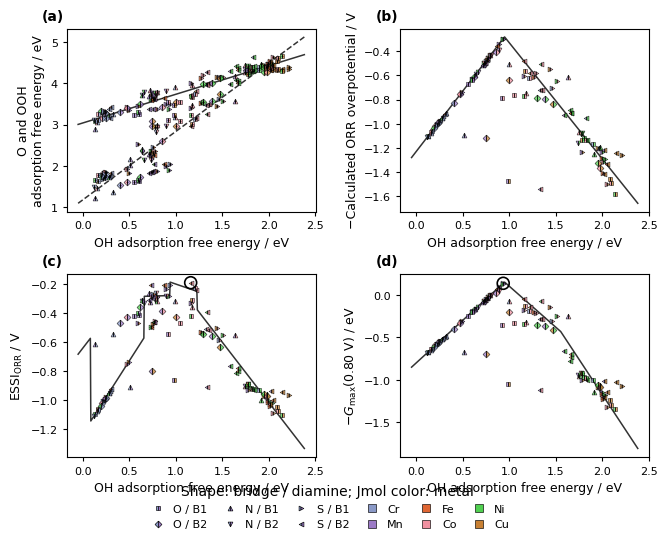

Saved Figure 3 analysis v27, 600 dpi PNG: Figure_3_activity_analysis_v27.png
Saved Figure 3 analysis v27 vector SVG: Figure_3_activity_analysis_v27.svg
Saved Figure 3 analysis v27 interactive four-panel figure: Figure_3_activity_analysis_v27_interactive.html


In [14]:
###########################################
##-Static four-panel exploratory analysis-##
###########################################

figure_width_cm  = 17.0
figure_height_cm = 14.5
largest_font_pt = 10
plt.rcParams.update({'font.size': largest_font_pt})
figure2, axes = plt.subplots(
    2, 2, figsize=(figure_width_cm/2.54, figure_height_cm/2.54),
)
figure2.subplots_adjust(
    left=0.11, right=0.98, top=0.92, bottom=0.17, wspace=0.34, hspace=0.34,
)
ax_a, ax_b, ax_c, ax_d = axes.ravel()

for _,row in results.iterrows():
    add_static_split_marker(ax_a,row,row['G_OH'],row['G_OOH'])
    add_static_split_marker(ax_a,row,row['G_OH'],row['G_O'],center_dot=True)
    for axis,y_column in [(ax_b,'negative_overpotential'),(ax_c,'ESSI_ORR'),(ax_d,'negative_G_max')]:
        add_static_split_marker(axis,row,row['G_OH'],row[y_column])

ax_a.plot(descriptor_grid, descriptor_OOH, color='#333333', linewidth=1.1, zorder=1)
ax_a.plot(descriptor_grid, descriptor_O, color='#333333', linewidth=1.1, linestyle='--', zorder=1)
ax_b.plot(descriptor_grid, -descriptor_overpotential, color='#333333', linewidth=1.1, zorder=1)
ax_c.plot(descriptor_grid, descriptor_ESSI, color='#333333', linewidth=1.1, zorder=1)
ax_d.plot(descriptor_grid, -descriptor_G_max, color='#333333', linewidth=1.1, zorder=1)

for axis, best_row, y_column in [
    (ax_c, best_essi, 'ESSI_ORR'),
    (ax_d, best_gmax, 'negative_G_max'),
]:
    axis.scatter(
        [best_row['G_OH']], [best_row[y_column]], facecolors='none',
        edgecolors='black', linewidths=1.2, s=74, zorder=5,
    )

axis_labels = [
    ('O and OOH\nadsorption free energy / eV', '(a)'),
    ('−Calculated ORR overpotential / V', '(b)'),
    (r'ESSI$_{\mathrm{ORR}}$ / V', '(c)'),
    (rf'$-G_{{\max}}$({GMAX_POTENTIAL:.2f} V) / eV', '(d)'),
]
for axis, (y_label, panel_label) in zip(axes.ravel(), axis_labels):
    axis.set_xlabel('OH adsorption free energy / eV')
    axis.set_ylabel(y_label)
    axis.text(
        -0.10, 1.03, panel_label, transform=axis.transAxes, clip_on=False,
        ha='left', va='bottom', fontsize=10, fontweight='bold',
    )
    axis.set_facecolor((1.0, 1.0, 1.0, 0.65))
    axis.tick_params(direction='out', width=0.8, length=3, colors='black')
    for spine in axis.spines.values():
        spine.set_color('black')
        spine.set_linewidth(0.8)

handles, labels = legend_marker_handles()
figure2.legend(
    handles, labels, loc='lower center', bbox_to_anchor=(0.50, 0.025),
    ncol=6, frameon=False, columnspacing=1.0, handletextpad=0.4,
    title='Shape: bridge / diamine; Jmol color: metal',
)
figure2.patch.set_facecolor('white')

if IN_COLAB:
    figure_output_dir = Path('/content')
else:
    figure_output_dir = Path('.') if Path.cwd().name == 'figure3_outputs' else Path('figure3_outputs')
figure_output_dir.mkdir(parents=True, exist_ok=True)
existing_figure_versions = []
for output_file in figure_output_dir.glob('Figure_3_activity_analysis_v*.png'):
    try:
        existing_figure_versions.append(int(output_file.stem.rsplit('_v', 1)[1]))
    except ValueError:
        pass
FIGURE_VERSION = max(existing_figure_versions + [1]) + 1
analysis_basename = f'Figure_3_activity_analysis_v{FIGURE_VERSION}'
figure_png = figure_output_dir / f'{analysis_basename}.png'
figure_svg = figure_output_dir / f'{analysis_basename}.svg'
figure_html = figure_output_dir / f'{analysis_basename}_interactive.html'
figure2.savefig(figure_png, dpi=600, facecolor='white', transparent=False)
figure2.savefig(figure_svg, format='svg', facecolor='white', transparent=False)
interactive_figure2.write_html(figure_html, include_plotlyjs=True)
plt.show()
print(f'Saved Figure 3 analysis v{FIGURE_VERSION}, 600 dpi PNG: {figure_png}')
print(f'Saved Figure 3 analysis v{FIGURE_VERSION} vector SVG: {figure_svg}')
print(f'Saved Figure 3 analysis v{FIGURE_VERSION} interactive four-panel figure: {figure_html}')


## Selectable free energy diagrams

Select a catalyst by its components: adsorption site, other metal, diamine and bridge.
Dialdehyde is not shown as a selector because every retained pathway uses A2. Only the
exact site-matched pathways that pass the energy filter are offered.
Hover over an energy level to inspect the catalyst, site, adsorption energies,
potential, limiting potential, overpotential and selected OOH orientation.

In [15]:
##############################################
##-Interactive free energy diagram function-##
##############################################

STATE_LABELS = ['* + O₂', 'OOH*', 'O*', 'OH*', '* + 2H₂O']
STATE_X = np.arange(5)


def free_energy_states(row, potential):
    return np.array(
        [
            ORR_FREE_ENERGY - 4*potential,
            row['G_OOH'] - 3*potential,
            row['G_O'] - 2*potential,
            row['G_OH'] - potential,
            0.0,
        ]
    )


def empty_free_energy_figure(catalyst_name, site_row, reason):
    figure = go.Figure()
    figure.add_annotation(
        x=0.5, y=0.56, xref='paper', yref='paper', showarrow=False,
        text=f'<b>No exact complete pathway</b><br>{reason}', align='center',
    )
    figure.update_layout(
        title=f'{catalyst_name}, {site_row.ads_site} ({site_row.ads_metal})',
        width=600, height=430, margin=dict(l=65, r=15, t=55, b=60),
        font=dict(family='Arial, sans-serif', size=10, color='black'),
        paper_bgcolor='rgba(255,255,255,0.65)',
        plot_bgcolor='rgba(255,255,255,0.65)',
    )
    figure.update_xaxes(
        tickmode='array', tickvals=STATE_X, ticktext=STATE_LABELS,
        title='Reaction coordinate', range=[-0.35, 4.35],
        showline=True, linewidth=1, linecolor='black', mirror=True,
    )
    figure.update_yaxes(
        title='Free energy / eV', showline=True, linewidth=1,
        linecolor='black', mirror=True,
    )
    return figure


def free_energy_figure(catalyst_name, ads_site):
    site_rows = all_sites.loc[
        (all_sites['name'] == catalyst_name) & (all_sites['ads_site'] == ads_site)
    ]
    if site_rows.empty:
        raise KeyError(f'Unknown catalyst and adsorption site key: {catalyst_name}, {ads_site}')

    site_row = site_rows.iloc[0]
    selected = results.loc[
        (results['name'] == catalyst_name) & (results['ads_site'] == ads_site)
    ]

    if selected.empty:
        missing = []
        if pd.isna(site_row['E_tot_OH']):
            missing.append('OH')
        if pd.isna(site_row['E_tot_O']):
            missing.append('O')
        if pd.isna(site_row['E_tot_OOH']):
            missing.append('OOH')
        reason = 'Missing or unverified same-site value(s): ' + ', '.join(missing)
        return empty_free_energy_figure(catalyst_name, site_row, reason)

    row = selected.iloc[0]
    potentials = [
        ('U = 0.00 V', 0.0, colors[0]),
        (f'U = U<sub>L</sub> = {row["U_L"]:.2f} V', row['U_L'], colors[2]),
        (f'U = U<sub>eq</sub> = {U_EQ:.2f} V', U_EQ, colors[1]),
    ]
    figure = go.Figure()

    for label, potential, color in potentials:
        energies = free_energy_states(row, potential)

        ##-Thick horizontal lines represent the free energy of each ORR state-##
        level_x, level_y = [], []
        for x_value, energy in zip(STATE_X, energies):
            level_x.extend([x_value - 0.20, x_value + 0.20, None])
            level_y.extend([energy, energy, None])
        figure.add_trace(
            go.Scatter(
                x=level_x, y=level_y, mode='lines', name=label,
                line=dict(color=color, width=4), hoverinfo='skip',
            )
        )

        ##-Thin dotted connectors-##
        connector_x, connector_y = [], []
        for index in range(4):
            connector_x.extend([STATE_X[index] + 0.20, STATE_X[index + 1] - 0.20, None])
            connector_y.extend([energies[index], energies[index + 1], None])
        figure.add_trace(
            go.Scatter(
                x=connector_x, y=connector_y, mode='lines', showlegend=False,
                line=dict(color=color, width=1, dash='dot'), hoverinfo='skip',
            )
        )

        customdata = np.column_stack(
            [
                np.repeat(row['name'], 5), np.repeat(row['ads_site'], 5),
                np.repeat(row['ads_metal'], 5), np.repeat(row['G_OH'], 5),
                np.repeat(row['G_O'], 5), np.repeat(row['G_OOH'], 5),
                np.repeat(row['U_L'], 5), np.repeat(row['overpotential'], 5),
                np.repeat(row['potential_determining_step'], 5),
                np.repeat(row['OOH_orientation'], 5), np.repeat(potential, 5),
                STATE_LABELS,
            ]
        )
        figure.add_trace(
            go.Scatter(
                x=STATE_X, y=energies, mode='markers', showlegend=False,
                marker=dict(size=7, color=color, opacity=0.65, line=dict(color='black', width=0.8)),
                customdata=customdata,
                hovertemplate=(
                    '<b>%{customdata[0]}</b><br>'
                    'Adsorption site: %{customdata[1]} (%{customdata[2]})<br>'
                    'State: %{customdata[11]}<br>'
                    'Free energy: %{y:.2f} eV<br>'
                    'Applied potential: %{customdata[10]:.2f} V<br>'
                    'ΔG(OH*): %{customdata[3]:.2f} eV<br>'
                    'ΔG(O*): %{customdata[4]:.2f} eV<br>'
                    'ΔG(OOH*): %{customdata[5]:.2f} eV<br>'
                    'U<sub>L</sub>: %{customdata[6]:.2f} V<br>'
                    'η<sub>ORR</sub>: %{customdata[7]:.2f} V<br>'
                    'Potential-determining step: %{customdata[8]}<br>'
                    'Selected OOH orientation: %{customdata[9]}<extra></extra>'
                ),
            )
        )

    figure.update_layout(
        title=(
            f'{row["name"]}, {row["ads_site"]} ({row["ads_metal"]}); '
            f'η<sub>ORR</sub> = {row["overpotential"]:.2f} V'
        ),
        width=600, height=430, margin=dict(l=65, r=15, t=55, b=60),
        font=dict(family='Arial, sans-serif', size=10, color='black'),
        legend=dict(font=dict(size=8)), hovermode='closest',
        paper_bgcolor='rgba(255,255,255,0.65)',
        plot_bgcolor='rgba(255,255,255,0.65)',
    )
    figure.update_xaxes(
        tickmode='array', tickvals=STATE_X, ticktext=STATE_LABELS,
        title='Reaction coordinate', range=[-0.35, 4.35],
        showline=True, linewidth=1, linecolor='black', mirror=True, ticks='outside',
    )
    figure.update_yaxes(
        title='Free energy / eV', showline=True, linewidth=1,
        linecolor='black', mirror=True, ticks='outside', zeroline=True,
        zerolinecolor='gray', zerolinewidth=1,
    )
    return figure

In [16]:
#######################################
##-Catalyst component selectors-#######
#######################################

selector_layout = widgets.Layout(width='330px')
selector_style = {'description_width': '120px'}

ads_metal_dropdown = widgets.Dropdown(
    description='Adsorption site:', layout=selector_layout, style=selector_style
)
other_metal_dropdown = widgets.Dropdown(
    description='Other metal:', layout=selector_layout, style=selector_style
)
base_dropdown = widgets.Dropdown(
    description='Diamine:', layout=selector_layout, style=selector_style
)
bridge_dropdown = widgets.Dropdown(
    description='Bridge:', layout=selector_layout, style=selector_style
)
diagram_output = widgets.Output()
selector_status = widgets.HTML()
selector_widgets = [
    ads_metal_dropdown, other_metal_dropdown, base_dropdown, bridge_dropdown,
]
_updating_selectors = False


def set_dropdown_options(dropdown, values, preferred=None):
    values = list(values)
    old_value = dropdown.value
    dropdown.options = values
    if preferred in values:
        dropdown.value = preferred
    elif old_value in values:
        dropdown.value = old_value
    elif values:
        dropdown.value = values[0]


def selected_component_rows():
    return results.loc[
        results['ads_metal'].eq(ads_metal_dropdown.value)
        & results['other_metal'].eq(other_metal_dropdown.value)
        & results['diamine'].eq(base_dropdown.value)
        & results['bridge'].eq(bridge_dropdown.value)
    ]


def redraw_diagram():
    selected = selected_component_rows()
    with diagram_output:
        diagram_output.clear_output(wait=True)
        if selected.empty:
            selector_status.value = '<b>No retained catalyst matches this combination.</b>'
        else:
            row = selected.iloc[0]
            selector_status.value = (
                f'<b>{row["name"]}</b> &nbsp; '
                f'({row["ads_site"]}; adsorption on {row["ads_metal"]})'
            )
            free_energy_figure(row['name'], row['ads_site']).show(
                renderer=PLOTLY_RENDERER
            )


def update_component_selectors(change=None):
    global _updating_selectors
    if _updating_selectors:
        return

    _updating_selectors = True
    best = results.iloc[0]
    try:
        set_dropdown_options(
            ads_metal_dropdown,
            [metal for metal in metal_order if metal in set(results['ads_metal'])],
            preferred=best['ads_metal'] if change is None else None,
        )
        subset = results.loc[results['ads_metal'].eq(ads_metal_dropdown.value)]
        set_dropdown_options(
            other_metal_dropdown,
            [metal for metal in metal_order if metal in set(subset['other_metal'])],
            preferred=best['other_metal'] if change is None else None,
        )
        subset = subset.loc[subset['other_metal'].eq(other_metal_dropdown.value)]
        set_dropdown_options(
            base_dropdown, [value for value in ('B1', 'B2') if value in set(subset['diamine'].dropna())],
            preferred=best['diamine'] if change is None else None,
        )
        subset = subset.loc[subset['diamine'].eq(base_dropdown.value)]
        bridge_order = {'N': 0, 'O': 1, 'S': 2}
        bridge_values = sorted(
            subset['bridge'].dropna().unique(),
            key=lambda value: tuple(bridge_order.get(atom, 9) for atom in value if atom in bridge_order),
        )
        set_dropdown_options(
            bridge_dropdown, bridge_values,
            preferred=best['bridge'] if change is None else None,
        )
    finally:
        _updating_selectors = False
    redraw_diagram()


for dropdown in selector_widgets:
    dropdown.observe(update_component_selectors, names='value')
update_component_selectors()

display(
    widgets.VBox(
        [
            ads_metal_dropdown,
            other_metal_dropdown,
            base_dropdown,
            bridge_dropdown,
            selector_status,
            diagram_output,
        ],
        layout=widgets.Layout(align_items='flex-start'),
    )
)

## Figure 3: scaling relations and classical ORR volcano

Marker color and shape identify the adsorption-center metal. O uses a thin, centered vertical stroke; OOH uses the unmarked family symbol. The interactive plot appears first and retains catalyst, adsorption-center, and adsorption-energy details on hover. The static figure is exported as versioned PNG, SVG, and PDF files with an opaque white background.


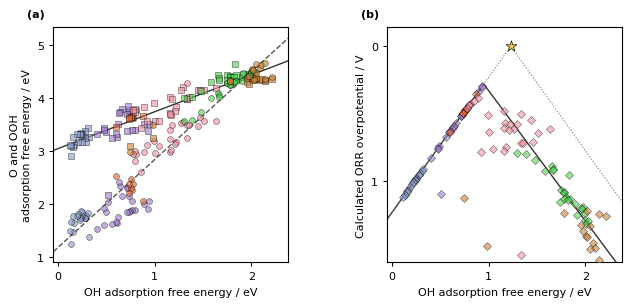

Saved Figure 3 v28: Figure_3_scaling_relations_v28.png


In [17]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import plotly.graph_objects as go
from plotly.subplots import make_subplots

figure_width_cm, figure_height_cm, largest_font_pt = 17.0, 8.5, 8
plt.rcParams.update({'font.size': largest_font_pt, 'axes.labelsize': largest_font_pt, 'xtick.labelsize': largest_font_pt, 'ytick.labelsize': largest_font_pt})

metal_order = ['Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu']
jmol_colors = {
    'Cr': '#8A99C7', 'Mn': '#9C7AC7', 'Fe': '#E06633',
    'Co': '#F090A0', 'Ni': '#50D050', 'Cu': '#C88033',
}
mpl_markers = {'OOH': 's', 'O': 'o', 'volcano': 'D'}
plotly_markers = {'OOH': 'square', 'O': 'circle', 'volcano': 'diamond'}

hover_columns = ['name', 'ads_site', 'ads_metal', 'metal1', 'metal2', 'bridge',
                 'diamine', 'G_OH', 'G_O', 'G_OOH', 'overpotential']
custom = results[hover_columns].to_numpy()
hover = ('<b>%{customdata[0]}</b><br>Adsorption site: %{customdata[1]} (%{customdata[2]})'
         '<br>Metal pair: %{customdata[3]}–%{customdata[4]}'
         '<br>Bridge: %{customdata[5]}<br>Diamine: %{customdata[6]}'
         '<br>OH adsorption free energy: %{customdata[7]:.2f} eV'
         '<br>O adsorption free energy: %{customdata[8]:.2f} eV'
         '<br>OOH adsorption free energy: %{customdata[9]:.2f} eV'
         '<br>CHE overpotential: %{customdata[10]:.2f} V<extra></extra>')

# Interactive two-panel plot is shown before the static publication exports.
interactive = make_subplots(rows=1, cols=2, horizontal_spacing=0.17)
for metal in metal_order:
    group = results.loc[results.ads_metal == metal]
    if group.empty:
        continue
    group_custom = group[hover_columns].to_numpy()
    interactive.add_trace(go.Scatter(
        x=group.G_OH, y=group.G_OOH, mode='markers', name=metal, zorder=2,
        legendgroup=metal, showlegend=False,
        marker=dict(color=jmol_colors[metal], symbol=plotly_markers['OOH'],
          size=6, opacity=0.62, line=dict(color='black', width=0.45)),
        customdata=group_custom, hovertemplate='<b>OOH</b><br>'+hover,
    ), row=1, col=1)
    interactive.add_trace(go.Scatter(
        x=group.G_OH, y=group.G_O, mode='markers', name=metal, zorder=2,
        legendgroup=metal, showlegend=False,
        marker=dict(color=jmol_colors[metal], symbol=plotly_markers['O'],
          size=6, opacity=0.62, line=dict(color='black', width=0.45)),
        customdata=group_custom, hovertemplate='<b>O</b><br>'+hover,
    ), row=1, col=1)
    interactive.add_trace(go.Scatter(
        x=group.G_OH, y=group.overpotential, mode='markers', name=metal, zorder=2,
        legendgroup=metal, showlegend=False,
        marker=dict(color=jmol_colors[metal], symbol=plotly_markers['volcano'],
          size=6, opacity=0.58, line=dict(color='black', width=0.45)),
        customdata=group_custom, hovertemplate='<b>CHE activity</b><br>'+hover,
    ), row=1, col=2)

interactive.add_trace(go.Scatter(x=descriptor_grid, y=descriptor_OOH, mode='lines', zorder=0,
    name='OOH–OH scaling', line=dict(color='#333333', width=1.2), hoverinfo='skip'), row=1, col=1)
interactive.add_trace(go.Scatter(x=descriptor_grid, y=descriptor_O, mode='lines', zorder=0,
    name='O–OH scaling', line=dict(color='#555555', width=1.2, dash='dash'), hoverinfo='skip'), row=1, col=1)
interactive.add_trace(go.Scatter(x=descriptor_grid, y=descriptor_overpotential, mode='lines', zorder=0,
    name='Scaling-derived CHE', line=dict(color='#333333', width=1.2), hoverinfo='skip'), row=1, col=2)
ideal_x = np.linspace(*descriptor_limits, 401)
ideal_eta = 1.23 - np.minimum(ideal_x, 4.92 - (ideal_x + 2.46))
interactive.add_trace(go.Scatter(x=ideal_x, y=ideal_eta, mode='lines', zorder=0,
    name='Ideal CHE reference', line=dict(color='#777777', width=0.9, dash='dot'), hoverinfo='skip'), row=1, col=2)
interactive.add_trace(go.Scatter(x=[1.23], y=[0.0], mode='markers', name='Ideal limit', zorder=3,
    marker=dict(symbol='star', size=10, color='#F2C14E', line=dict(color='black', width=0.55)),
    hovertemplate='OH adsorption free energy: 1.23 eV<br>Overpotential: 0.00 V<extra></extra>'), row=1, col=2)
eta_tick_max = float(np.ceil(results.overpotential.max()/0.2)*0.2)
interactive.update_layout(width=1250, height=560, paper_bgcolor='white', plot_bgcolor='white',
    font=dict(family='Arial, sans-serif', size=8, color='black'),
    margin=dict(l=85, r=55, t=35, b=75), showlegend=False, hovermode='closest')
interactive.update_xaxes(title_text='OH adsorption free energy / eV', range=list(descriptor_limits),
    tickmode='array', tickvals=[0, 1, 2], ticktext=['0', '1', '2'],
    showline=True, linewidth=1, linecolor='black', mirror=True, row=1, col=1)
interactive.update_xaxes(title_text='OH adsorption free energy / eV', range=list(descriptor_limits),
    tickmode='array', tickvals=[0, 1, 2], ticktext=['0', '1', '2'],
    showline=True, linewidth=1, linecolor='black', mirror=True, row=1, col=2)
interactive.update_yaxes(title_text='O and OOH<br>adsorption free energy / eV',
    tickmode='array', tickvals=[1, 2, 3, 4, 5], ticktext=['1', '2', '3', '4', '5'],
    showline=True, linewidth=1, linecolor='black', mirror=True, row=1, col=1)
interactive.update_yaxes(title_text='Calculated ORR overpotential / V',
    range=[eta_tick_max, -0.14], tickmode='array',
    tickvals=[0, 1, 2], ticktext=['0', '1', '2'],
    showline=True, linewidth=1, linecolor='black', mirror=True, row=1, col=2)
interactive.add_annotation(x=-0.11, y=1.04, xref='x domain', yref='y domain', text='(a)',
    showarrow=False, font=dict(size=8), xanchor='right', yanchor='bottom')
interactive.add_annotation(x=-0.11, y=1.04, xref='x2 domain', yref='y2 domain', text='(b)',
    showarrow=False, font=dict(size=8), xanchor='right', yanchor='bottom')
interactive.show()

final_figure, (ax_scaling, ax_volcano) = plt.subplots(
    1, 2, figsize=(figure_width_cm/2.54, figure_height_cm/2.54))
final_figure.subplots_adjust(left=0.13, right=0.98, top=0.88, bottom=0.16, wspace=0.42)
for metal in metal_order:
    group = results.loc[results.ads_metal == metal]
    if group.empty:
        continue
    scaling_style = dict(s=18, c=jmol_colors[metal], alpha=0.62,
                         edgecolors='black', linewidths=0.4, zorder=3)
    volcano_style = dict(marker=mpl_markers['volcano'], s=17, c=jmol_colors[metal],
                         alpha=0.58, edgecolors='black', linewidths=0.4, zorder=3)
    ax_scaling.scatter(group.G_OH, group.G_OOH, marker=mpl_markers['OOH'],
        **scaling_style)
    ax_scaling.scatter(group.G_OH, group.G_O, marker=mpl_markers['O'],
        **scaling_style)
    ax_volcano.scatter(group.G_OH, group.overpotential, **volcano_style)

ax_scaling.plot(descriptor_grid, descriptor_OOH, color='#333333', linewidth=1.0, zorder=1)
ax_scaling.plot(descriptor_grid, descriptor_O, color='#555555', linewidth=1.0, linestyle='--', zorder=1)
ax_volcano.plot(descriptor_grid, descriptor_overpotential, color='#333333', linewidth=1.0, zorder=1)
ax_volcano.plot(ideal_x, ideal_eta, color='#777777', linewidth=0.8, linestyle=':', zorder=1)
ax_volcano.scatter([1.23], [0.0], marker='*', s=66, facecolor='#F2C14E',
    edgecolor='black', linewidths=0.45, zorder=5)
ax_scaling.set_xlabel('OH adsorption free energy / eV')
ax_scaling.set_ylabel('O and OOH\nadsorption free energy / eV')
ax_volcano.set_xlabel('OH adsorption free energy / eV')
ax_volcano.set_ylabel('Calculated ORR overpotential / V')
ax_scaling.set_xticks([0, 1, 2])
ax_scaling.set_yticks([1, 2, 3, 4, 5])
ax_volcano.set_xticks([0, 1, 2])
ax_volcano.set_yticks([0, 1, 2])
ax_volcano.set_ylim(eta_tick_max, -0.14)
for axis, panel in ((ax_scaling, '(a)'), (ax_volcano, '(b)')):
    axis.set_xlim(*descriptor_limits)
    axis.set_box_aspect(1)
    axis.tick_params(direction='out', width=0.8, length=3, labelsize=8, colors='black')
    axis.text(-0.11, 1.035, panel, transform=axis.transAxes, clip_on=False,
        ha='left', va='bottom', fontsize=8, fontweight='bold')
    axis.set_facecolor('white')
    for spine in axis.spines.values():
        spine.set_color('black')
        spine.set_linewidth(0.8)
# Marker colors and adsorbate-specific shapes are decoded in the Figure 3 caption.
final_figure.patch.set_facecolor('white')

if IN_COLAB:
    figure_output_dir = Path('/content')
else:
    figure_output_dir = Path('.') if Path.cwd().name == 'figure3_outputs' else Path('figure3_outputs')
figure_output_dir.mkdir(parents=True, exist_ok=True)
existing_versions = [int(path.stem.rsplit('_v', 1)[1]) for path in figure_output_dir.glob('Figure_3_scaling_relations_v*.png') if path.stem.rsplit('_v', 1)[1].isdigit()]
FIGURE_VERSION = max(existing_versions, default=21) + 1
base = figure_output_dir / f'Figure_3_scaling_relations_v{FIGURE_VERSION}'
interactive_path = base.parent / f'{base.name}_interactive.html'
if any(base.with_suffix(ext).exists() for ext in ('.png', '.svg', '.pdf')) or interactive_path.exists():
    raise FileExistsError(f'Figure 3 v{FIGURE_VERSION} output already exists.')
interactive.write_html(interactive_path, include_plotlyjs=True)
final_figure.savefig(base.with_suffix('.png'), dpi=600, facecolor='white', transparent=False)
final_figure.savefig(base.with_suffix('.svg'), format='svg', facecolor='white', transparent=False)
final_figure.savefig(base.with_suffix('.pdf'), format='pdf', facecolor='white', transparent=False)
plt.show()
print(f'Saved Figure 3 v{FIGURE_VERSION}: {base.with_suffix(".png")}')
